In [18]:
import pandas as pd
import numpy as np, matplotlib.pyplot as plt

In [41]:
df = pd.read_csv("../data/alto_100280000_100299999.csv")

In [42]:
# we count the following languages as SAMI
SAMI = {"sme", "sma", "smj", "smn", "sms"}

In [43]:
# we treat all Sami languages as one group a
coarse = lambda s: s.where(~s.isin(SAMI), "sami").replace({"nob": "nor", "nno": "nor"})

In [45]:
agree = coarse(df.glotlid_lang) == coarse(df.gielladetect_lang)
sami_any = df.glotlid_lang.isin(SAMI) | df.gielladetect_lang.isin(SAMI)
cap = lambda s: s.clip(upper=300)

In [46]:
all_len = agree.groupby(cap(df.len_para_text)).agg(["size", "mean"])
sami_len = agree[sami_any].groupby(cap(df.len_para_text[sami_any])).agg(["size", "mean"])

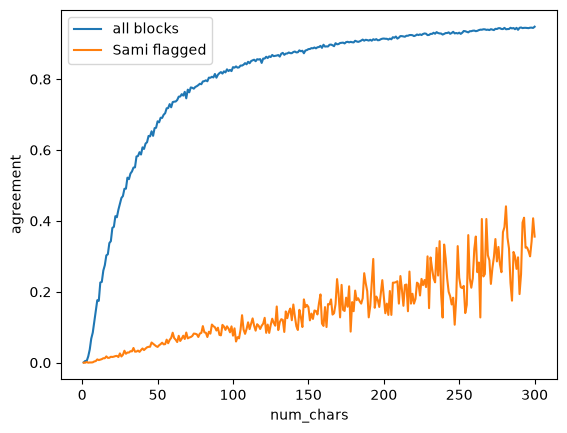

In [47]:
ax = all_len["mean"].plot(label="all blocks")
sami_len["mean"].plot(ax=ax, label="Sami flagged", ylabel="agreement", xlabel="num_chars")
ax.legend(); plt.show()

In [ ]:
# Look at all

In [51]:
MIN_CHARS = 40  # replace with the threshold from the length analysis
g_sami = df.glotlid_lang.isin(SAMI)
z_sami = df.gielladetect_lang.isin(SAMI)
long = df.len_para_text >= MIN_CHARS

flags = pd.DataFrame({"glotlid": g_sami, "gielladetect": z_sami, "either": g_sami | z_sami, "both": g_sami & z_sami})
counts = pd.DataFrame({"all blocks": flags.groupby(df.dhlabid).any().sum(),
                       f">= {MIN_CHARS} chars": flags[long].groupby(df.dhlabid[long]).any().sum()})
print(f"{df.dhlabid.nunique()} books in total"); print(counts)

16917 books in total
              all blocks  >= 40 chars
glotlid             6485         4943
gielladetect       16130         9326
either             16222        10605
both                1285          573
